# Churn Radar · prevendo cancelamento de clientes de telecom

Notebook completo, da limpeza à avaliação: qual cliente vai cancelar, e por quê?

- **Dados:** Telco Customer Churn (IBM), 7.043 clientes.
- **Método:** separação treino/teste estratificada, `Pipeline` com pré-processamento, comparação de 4 modelos por validação cruzada de 5 dobras e uma única avaliação no teste.
- **Resultado:** Regressão Logística com **ROC-AUC 0,84** no teste, empatada com Random Forest e Gradient Boosting, e escolhida por ser explicável.

Código organizado em módulos, com testes e CI: [github.com/jgcortezi/customer-churn-prediction](https://github.com/jgcortezi/customer-churn-prediction)

In [1]:
import glob

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, confusion_matrix, make_scorer,
                             precision_score, recall_score, roc_auc_score)
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

RANDOM_STATE = 42

# No Kaggle, o arquivo fica em /kaggle/input. Fora dele, baixa da fonte pública da IBM.
arquivos = glob.glob("/kaggle/input/**/*Telco*Churn*.csv", recursive=True)
fonte = arquivos[0] if arquivos else (
    "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
)
raw = pd.read_csv(fonte)
raw.shape

(7043, 21)

## 1. Limpeza

`TotalCharges` veio como texto. Os 11 valores em branco são todos de clientes com `tenure = 0`, que ainda não pagaram nenhuma fatura, então o valor correto é **0**.

In [2]:
em_branco = raw["TotalCharges"].str.strip() == ""
print(em_branco.sum(), "em branco; tenure dessas linhas:", raw.loc[em_branco, "tenure"].unique())

df = raw.copy()
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"].str.strip(), errors="coerce").fillna(0.0)
df["SeniorCitizen"] = df["SeniorCitizen"].map({0: "No", 1: "Yes"})
df["Churn"] = df["Churn"].map({"No": 0, "Yes": 1})
print(f"Taxa de churn: {df['Churn'].mean():.1%}")

11 em branco; tenure dessas linhas: [0]
Taxa de churn: 26.5%


## 2. O que se relaciona com o cancelamento

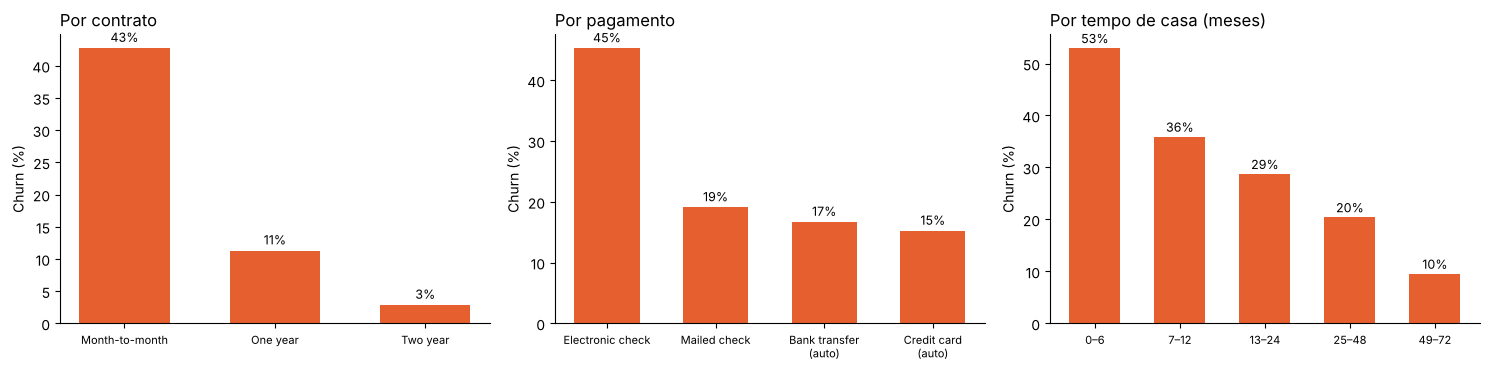

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
faixas = pd.cut(df["tenure"], [-1, 6, 12, 24, 48, 72], labels=["0–6", "7–12", "13–24", "25–48", "49–72"])
for ax, serie, titulo in [
    (axes[0], df.groupby("Contract")["Churn"].mean(), "Por contrato"),
    (axes[1], df.groupby("PaymentMethod")["Churn"].mean().sort_values(ascending=False), "Por pagamento"),
    (axes[2], df.groupby(faixas, observed=True)["Churn"].mean(), "Por tempo de casa (meses)"),
]:
    ax.bar(range(len(serie)), serie.values * 100, color="#e6602f", width=0.6)
    ax.set_xticks(range(len(serie)), [str(i).replace(" (automatic)", "\n(auto)") for i in serie.index], fontsize=8)
    for i, v in enumerate(serie.values):
        ax.text(i, v * 100 + 1, f"{v:.0%}", ha="center", fontsize=9)
    ax.set_title(titulo, loc="left")
    ax.set_ylabel("Churn (%)")
    ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()

- **Contrato mensal** cancela cerca de 15 vezes mais que o de 2 anos.
- **Cheque eletrônico** cancela quase 3 vezes mais que cartão automático.
- **Quem cancela, cancela cedo:** mais da metade nos primeiros 6 meses.

## 3. Treino e teste

Separo 20% para teste **antes** de qualquer modelagem. Todo o pré-processamento fica dentro do `Pipeline`, para não vazar informação.

In [4]:
X = df.drop(columns=["Churn", "customerID"])
y = df["Churn"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

numericas = ["tenure", "MonthlyCharges", "TotalCharges"]
categoricas = [c for c in X.columns if c not in numericas]
prep = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("esc", StandardScaler())]), numericas),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categoricas),
], verbose_feature_names_out=False)

modelos = {
    "Baseline": DummyClassifier(strategy="most_frequent"),
    "Regressão Logística": LogisticRegression(class_weight="balanced", max_iter=2000, random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=400, min_samples_leaf=5, class_weight="balanced",
                                            n_jobs=-1, random_state=RANDOM_STATE),
    "Gradient Boosting": HistGradientBoostingClassifier(learning_rate=0.05, max_iter=300, max_leaf_nodes=15,
                                                        class_weight="balanced", random_state=RANDOM_STATE),
}
cv = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE)
scoring = {"roc_auc": "roc_auc", "pr_auc": "average_precision", "recall": "recall",
           "precision": make_scorer(precision_score, zero_division=0), "f1": "f1"}
linhas = []
for nome, modelo in modelos.items():
    r = cross_validate(Pipeline([("prep", prep), ("modelo", modelo)]), X_train, y_train, cv=cv, scoring=scoring)
    linhas.append({"modelo": nome, **{k: r[f"test_{k}"].mean() for k in scoring}, "auc_desvio": r["test_roc_auc"].std()})
pd.DataFrame(linhas).sort_values("roc_auc", ascending=False).round(3)

,modelo,roc_auc,pr_auc,recall,precision,f1,auc_desvio
1,Regressão Logística,0.846,0.660,0.801,0.517,0.628,0.012
2,Random Forest,0.845,0.653,0.762,0.540,0.632,0.009
3,Gradient Boosting,0.841,0.657,0.769,0.536,0.631,0.009
0,Baseline,0.500,0.265,0.000,0.000,0.000,0.000


Os três modelos de verdade ficam empatados: a diferença de ROC-AUC é menor que o desvio entre as dobras. Com empate, escolho a **Regressão Logística**, mais simples e explicável.

## 4. Avaliação final no teste (uma única vez)

In [5]:
final = Pipeline([("prep", prep), ("modelo", modelos["Regressão Logística"])]).fit(X_train, y_train)
proba = final.predict_proba(X_test)[:, 1]
pred = (proba >= 0.5).astype(int)
top20 = np.argsort(-proba)[: int(len(proba) * 0.2)]
print(f"ROC-AUC:  {roc_auc_score(y_test, proba):.3f}")
print(f"PR-AUC:   {average_precision_score(y_test, proba):.3f}")
print(f"Recall:   {recall_score(y_test, pred):.1%}")
print(f"Precisão: {precision_score(y_test, pred):.1%}")
print(f"Os 20% de maior risco concentram {y_test.to_numpy()[top20].sum() / y_test.sum():.0%} dos churns")
confusion_matrix(y_test, pred)

ROC-AUC:  0.842
PR-AUC:   0.633
Recall:   78.3%
Precisão: 50.4%
Os 20% de maior risco concentram 50% dos churns


array([[747, 288],
       [ 81, 293]])

O resultado no teste bate com a validação cruzada, então o modelo **não decorou o treino**. Para o time de retenção: ligando só para os 20% de maior risco, alcança cerca de metade de todos os que iam cancelar.

## 5. Limitações

- O `class_weight="balanced"` deixa o risco **descalibrado**: serve para ordenar clientes, não como probabilidade exata.
- Variáveis muito correlacionadas (`MonthlyCharges`, `TotalCharges` e os serviços) dividem o efeito entre si, então o sinal de cada coeficiente sozinho pode enganar.
- Base fictícia de um único período: em produção, seria preciso retreinar e monitorar.